# Forecasting the yearly LSST footprints: `keiths_double_stripes_timing_bands`

The new rolling cadence does not reach a uniform WFD depth until late in the survey.  For
the early data releases the analysis has to pick a **sub-footprint that can be brought to
one constant depth**, and that choice sets both the area and the depth.  This notebook takes
the simulated per-year coadded $i$-band $5\sigma$ depth maps and turns them into
$(A,\ n_{\rm eff})$ and a Fisher forecast for **Y1, Y2, Y4, Y6 and Y10**.

$$\text{depth map (year)} \;\longrightarrow\; \text{boxes} \;\longrightarrow\;
  (A,\ m_5) \;\longrightarrow\; i_{\rm lim}=m_5-1 \;\longrightarrow\;
  n_{\rm eff}^{(b)}\ \text{(Cardinal, per bin)} \;\longrightarrow\; \text{forecast}$$

### How the footprint is chosen (M. Becker's prescription)

- Use the **outlined regions** of each year's map ([`rubin_lsst_map.pdf`](rubin_lsst_map.pdf)):
  the two **rolling stripes** that are being boosted in that year.  Y3, Y5, Y7-Y9 are skipped.
- **Ignore the bright extra single stripe** -- it sits inside the northern box and is simply
  downgraded to the box depth.
- Find a depth at which **the entire area can be made constant**: the year is limited by its
  shallowest box ("in Y2 we'd be limited by the less visited rolling stripe in the south").
- Y6 and Y10: **all** of the footprint.

### Choices made here

| step | choice |
|---|---|
| depth map | `iband_depth_keiths_double_stripes_timing_bands`, nside=128, coadded $i$-band $m_5$ |
| footprint cut | $\|b\| > 20^\circ$ in every year; Y6/Y10 "all" also drops $\delta<-75^\circ$ (the shallow polar strip) |
| depth of a box | **median** $m_5$ of the pixels inside it |
| depth of a year | **minimum** of its box medians |
| southern stripe on the far side of RA=180 | kept, although only 37 deg$^2$ survive $\|b\|>20^\circ$; it can set the depth of a year |
| $m_5\to$ sample cut | $i_{\rm lim}=m_5-1.0$ (SRD convention: Y1 $m_5\approx25.1\to i<24.1$, Y10 $m_5\approx26.3\to i<25.3$) |
| $n_{\rm eff}$ | the Cardinal relation of [`wfd_footprint_depth_tradeoff.ipynb`](wfd_footprint_depth_tradeoff.ipynb): per bin, $f_b=N(i<i_{\rm lim})/N(i<24.1)$ in $\|z-z_b\|<0.05$ |
| everything else | as in that notebook: Cardinal 1yr $n(z)$ shape, photo-z prior, Y1 lens preset, $\sigma_e=0.26$, $300<\ell<1800$ |


In [1]:
import numpy as np
import pandas as pd
import healpy as hp
import pyarrow.parquet as pq
import qp
import tables_io
from astropy.io import fits
from matplotlib import pyplot as plt
from matplotlib.colors import BoundaryNorm

from fisherA2Z.fisher_flex import FisherFlex

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

FULL_SKY_DEG2 = 4 * np.pi * (180.0 / np.pi) ** 2

DEPTH_MAP = "iband_depth_keiths_double_stripes_timing_bands.fits (1).gz"   # nside=128, 10 years
NZDC = "../nzdc_example"
MOCK = "../data/25/part-0.pq"          # local copy of pz_challenge_cardinal_gold/25/part-0.pq

YEARS = (1, 2, 4, 6, 10)
B_MIN = 20.0              # |galactic latitude| cut, deg, applied in every year
DEC_MIN_ALL = -75.0       # Y6/Y10 "all": drop the shallow south-polar strip
M5_TO_ILIM = 1.0          # i_lim = m5 - 1.0

M_SRC_FID = 24.1          # the depth the Cardinal 1yr n_eff corresponds to
NEFF_LENS_TOTAL = 18.0    # SRD Y1 lens total, arcmin^-2 -- defines the reference lens depth
LENS_ZMAX = 1.2
Z_HALFWIDTH = 0.05

SIGMA_E = 0.26
ELL_CUTS = dict(ell_min_cs=300, ell_max_cs=1800)
AREA_REF = 17500.0        # the reference footprint of the two earlier notebooks

SRC_C, LENS_C = "#2a78d6", "#eb6834"      # validated categorical pair (as in the other notebooks)


## 1. The depth maps

Each year of the file is the coadded $i$-band $5\sigma$ depth after that many years, `NaN`
outside the survey.  Galactic latitude is computed once per pixel for the $|b|>20^\circ$ cut.

In [2]:
depth = fits.open(DEPTH_MAP)[1].data            # (10 years, npix)
NSIDE = hp.npix2nside(depth.shape[1])
PIX_DEG2 = hp.nside2pixarea(NSIDE, degrees=True)

ra, dec = hp.pix2ang(NSIDE, np.arange(depth.shape[1]), lonlat=True)
theta_g, _ = hp.Rotator(coord=["C", "G"])(np.radians(90.0 - dec), np.radians(ra))
gal_b = 90.0 - np.degrees(theta_g)
HIGH_B = np.abs(gal_b) > B_MIN

print(f"nside={NSIDE}, pixel area {PIX_DEG2:.4f} deg^2")
print(pd.DataFrame({
    "mapped area": [np.isfinite(depth[y - 1]).sum() * PIX_DEG2 for y in YEARS],
    "... with |b|>20": [(np.isfinite(depth[y - 1]) & HIGH_B).sum() * PIX_DEG2 for y in YEARS],
    "median m5": [np.nanmedian(depth[y - 1]) for y in YEARS],
}, index=pd.Index([f"Y{y}" for y in YEARS], name="year")).to_string(float_format=lambda v: f"{v:9.2f}"))


nside=128, pixel area 0.2098 deg^2
      mapped area  ... with |b|>20  median m5
year                                         
Y1       13297.77         11739.20      25.00
Y2       14569.30         12723.27      25.39
Y4       19096.66         16103.32      25.67
Y6       19194.65         16185.15      25.95
Y10      19230.74         16213.05      26.26


## 2. The boxes

Matt's outlines, translated into RA/Dec rectangles.  On his Mollweide plots (RA increasing
to the left, centred on RA=0) every left-edge outline and its right-edge partner are the
**same region**, split by the RA=180$^\circ$ seam, so each pair is one box here.

| box | RA (east from -> to) | Dec | years |
|---|---|---|---|
| north stripe, far side | 110 -> 275 (Y1), 100 -> 280 | $-12$ to $+12$ | 1, 2, 4 |
| north stripe, centre (holds the bright single stripe) | 295 -> 100 | $-20$ to $+3$ | 2, 4 |
| south stripe, centre | 265 -> 125 | $-72$ to $-51$ | 2, 4 |
| south stripe, Y1 blob | 88 -> 125 | $-68$ to $-52$ | 1 |
| south stripe, far side | 150 -> 240 | $-55$ to $-41$ | 1, 2, 4 (37 deg$^2$ at $\|b\|>20^\circ$) |

The edges were set on the depth maps themselves, where each rolling stripe has a sharp
boundary in Dec and, in Y1, in RA (the timing bands).

In [3]:
def in_ra(lo, hi):
    '''RA interval going east from `lo` to `hi` (deg), wrap-aware.'''
    return ((ra - lo) % 360.0) <= ((hi - lo) % 360.0)


STRIPES = {
    "N far side": (100, 280, -12, 12),
    "N centre":   (295, 100, -20, 3),
    "S centre":   (265, 125, -72, -51),
    "S far side": (150, 240, -55, -41),
}
BOXES = {
    1: {"N far side": (110, 275, -12, 12), "S Y1 blob": (88, 125, -68, -52),
        "S far side": (150, 240, -55, -41)},
    2: STRIPES,
    4: STRIPES,
    6: None,    # all
    10: None,   # all
}


def box_mask(year, box):
    r0, r1, d0, d1 = box
    return in_ra(r0, r1) & (dec >= d0) & (dec < d1) & np.isfinite(depth[year - 1]) & HIGH_B


def year_regions(year):
    '''{region name: pixel mask} for one year, after the |b| cut.'''
    if BOXES[year] is None:
        return {"all": np.isfinite(depth[year - 1]) & HIGH_B & (dec > DEC_MIN_ALL)}
    return {name: box_mask(year, box) for name, box in BOXES[year].items()}


rows, regions = [], {}
for y in YEARS:
    regions[y] = year_regions(y)
    for name, msk in regions[y].items():
        rows.append({"year": f"Y{y}", "box": name, "area [deg^2]": msk.sum() * PIX_DEG2,
                     "p16": np.percentile(depth[y - 1][msk], 16),
                     "median m5": np.median(depth[y - 1][msk]),
                     "p84": np.percentile(depth[y - 1][msk], 84)})
box_table = pd.DataFrame(rows)
print(box_table.to_string(index=False, float_format=lambda v: f"{v:8.3f}"))


year        box  area [deg^2]      p16  median m5      p84
  Y1 N far side      2947.809   24.854     25.067   25.227
  Y1  S Y1 blob       175.832   25.078     25.204   25.318
  Y1 S far side        37.139   24.909     25.077   25.227
  Y2 N far side      2966.903   25.370     25.537   25.653
  Y2   N centre      3158.891   25.329     25.509   25.836
  Y2   S centre      1901.630   25.241     25.423   25.571
  Y2 S far side        37.139   25.375     25.498   25.595
  Y4 N far side      2967.742   25.665     25.798   25.910
  Y4   N centre      3161.409   25.723     25.901   26.097
  Y4   S centre      1902.469   25.659     25.815   25.949
  Y4 S far side        37.139   25.630     25.728   25.825
  Y6        all     15744.100   25.769     25.975   26.091
 Y10        all     15770.747   26.080     26.289   26.407


In [4]:
survey = []
for y in YEARS:
    meds = {n: np.median(depth[y - 1][m]) for n, m in regions[y].items()}
    limiting = min(meds, key=meds.get)
    area = sum(m.sum() for m in regions[y].values()) * PIX_DEG2
    m5 = meds[limiting]
    survey.append({"year": y, "area": area, "fsky": area / FULL_SKY_DEG2, "m5": m5,
                   "i_lim": m5 - M5_TO_ILIM, "limited by": limiting})
survey = pd.DataFrame(survey).set_index("year")
survey["delta_m"] = survey["i_lim"] - M_SRC_FID
print(survey.to_string(float_format=lambda v: f"{v:9.4f}"))


           area      fsky        m5     i_lim  limited by   delta_m
year                                                               
1     3160.7799    0.0766   25.0666   24.0666  N far side   -0.0334
2     8064.5628    0.1955   25.4228   24.4228    S centre    0.3228
4     8068.7593    0.1956   25.7283   24.7283  S far side    0.6283
6    15744.0997    0.3816   25.9752   24.9752         all    0.8752
10   15770.7472    0.3823   26.2887   25.2887         all    1.1887


### The footprints

Each map shows the depth of every surveyed pixel on one colour scale; the red outline
encloses the pixels that are **selected** as that year's footprint (boxes $\cap$ $|b|>20^\circ$,
and $\delta>-75^\circ$ for Y6/Y10).  Everything outside it is surveyed but not used.  The
solid black line is the Galactic plane and the dashed lines are $b=\pm20^\circ$.  The
histograms on the right are the depth distributions of the selected pixels in each box, with
the box median ticked; the dashed line is the depth the whole year is degraded to.

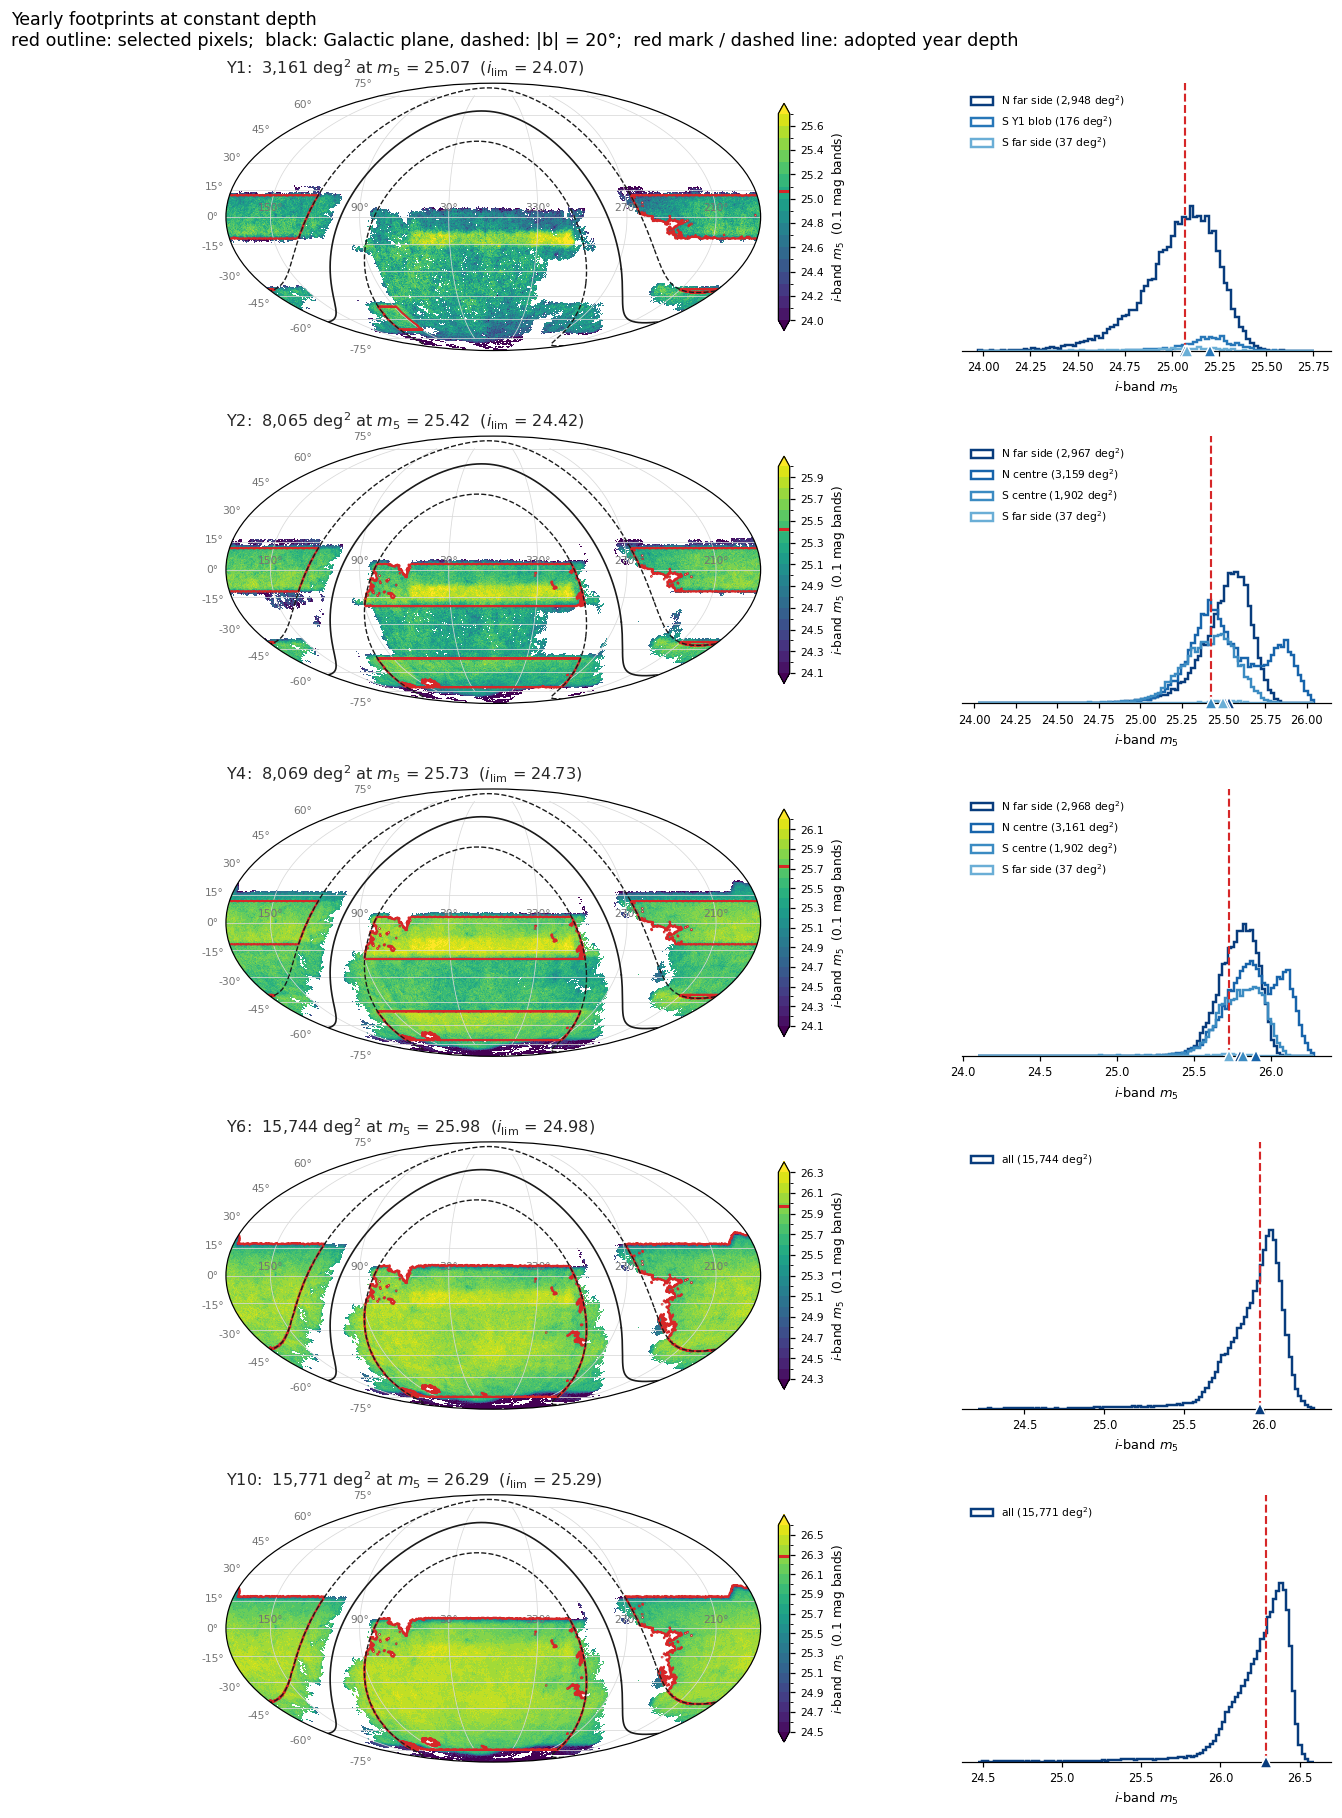

In [5]:
DEPTH_CMAP = plt.cm.viridis      # perceptually uniform, so equal colour steps = equal depth steps
DEPTH_STEP = 0.1                  # mag per colour band, so the depth can be read off the map
BOX_C = "#d62728"                 # red outline: stands out against every viridis colour
GRID_LON = np.linspace(-180, 180, 1441)
GRID_LAT = np.linspace(-90, 90, 721)
LON, LAT = np.meshgrid(GRID_LON, GRID_LAT)
GRID_PIX = hp.ang2pix(NSIDE, np.mod(-LON, 360.0), LAT, lonlat=True)   # x = -RA (east to the left)


def galactic_line(b_deg, n=2000):
    '''Mollweide (x, y) segments of the line of constant galactic latitude b, split at the seam.'''
    l = np.linspace(0, 360, n)
    th, ph = hp.Rotator(coord=["G", "C"])(np.radians(90.0 - np.full_like(l, b_deg)), np.radians(l))
    x = -np.radians(((np.degrees(ph) + 180.0) % 360.0) - 180.0)     # x = -RA, as for the maps
    yv = np.pi / 2 - th
    cut = np.where(np.abs(np.diff(x)) > np.pi)[0] + 1
    return list(zip(np.split(x, cut), np.split(yv, cut)))


GAL_LINES = {b: galactic_line(b) for b in (0.0, B_MIN, -B_MIN)}


fig = plt.figure(figsize=(12.5, 16.5))
gs = fig.add_gridspec(len(YEARS), 2, width_ratios=[2.4, 1], hspace=0.32, wspace=0.08,
                      top=0.955, bottom=0.03, left=0.03, right=0.98)
for k, y in enumerate(YEARS):
    m = depth[y - 1]
    used = np.zeros(m.size, bool)
    for msk in regions[y].values():
        used |= msk
    lo, hi = np.nanpercentile(m, [2, 99.5])      # one scale for selected and unselected pixels
    levels = np.arange(np.floor(lo / DEPTH_STEP) * DEPTH_STEP,
                       np.ceil(hi / DEPTH_STEP) * DEPTH_STEP + 1e-9, DEPTH_STEP)
    norm = BoundaryNorm(levels, DEPTH_CMAP.N, extend="both")

    ax = fig.add_subplot(gs[k, 0], projection="mollweide")
    pc = ax.pcolormesh(np.radians(LON), np.radians(LAT), m[GRID_PIX], cmap=DEPTH_CMAP,
                       norm=norm, shading="auto", rasterized=True)
    # outline of the selected pixels (traced on the 0.25 deg grid, so it follows pixel edges)
    ax.contour(np.radians(LON), np.radians(LAT), used[GRID_PIX].astype(float), levels=[0.5],
               colors=BOX_C, linewidths=1.3)
    for b, segs in GAL_LINES.items():
        for xs, ys in segs:
            ax.plot(xs, ys, color="0.1", lw=1.1 if b == 0 else 0.9, ls="-" if b == 0 else "--")
    ax.set_xticks(np.radians(np.arange(-150, 151, 60)))
    ax.set_xticklabels([f"{(-v) % 360:d}°" for v in np.arange(-150, 151, 60)], fontsize=7, color="0.45")
    ax.tick_params(axis="y", labelsize=7, labelcolor="0.45")
    ax.grid(True, color="0.85", lw=0.5)
    row = survey.loc[y]
    ax.set_title(f"Y{y}:  {row['area']:,.0f} deg$^2$ at $m_5$ = {row['m5']:.2f}  "
                 f"($i_{{\\rm lim}}$ = {row['i_lim']:.2f})", fontsize=10.5, loc="left", color="0.15")
    cb = fig.colorbar(pc, ax=ax, orientation="vertical", shrink=0.85, pad=0.02, extend="both")
    cb.set_ticks(levels[::2])
    cb.ax.axhline(row["m5"], color=BOX_C, lw=2)          # the adopted year depth
    cb.set_label(f"$i$-band $m_5$  ({DEPTH_STEP} mag bands)", fontsize=8)
    cb.ax.tick_params(labelsize=7)

    axh = fig.add_subplot(gs[k, 1])
    bins = np.arange(lo - 0.1, hi + 0.1, 0.02)
    names = list(regions[y])
    shades = plt.cm.Blues(np.linspace(0.95, 0.5, len(names)))
    for name, c in zip(names, shades):
        v = m[regions[y][name]]
        axh.hist(v, bins=bins, histtype="step", lw=1.6, color=c,
                 label=f"{name} ({regions[y][name].sum() * PIX_DEG2:,.0f} deg$^2$)")
        axh.plot(np.median(v), 0, "^", ms=8, color=c, mec="white", mew=1, clip_on=False, zorder=5)
    axh.axvline(row["m5"], color=BOX_C, ls="--", lw=1.4)
    axh.set_yticks([])
    axh.set_ylim(0, axh.get_ylim()[1] * (1.25 + 0.17 * len(names)))   # headroom for the legend
    axh.set_xlabel("$i$-band $m_5$", fontsize=8.5)
    axh.tick_params(labelsize=7.5)
    axh.legend(fontsize=7, frameon=False, loc="upper left")
    for s in ("top", "right", "left"):
        axh.spines[s].set_visible(False)

fig.suptitle("Yearly footprints at constant depth\nred outline: selected pixels;  black: Galactic plane, dashed: |b| = 20°;  red mark / dashed line: adopted year depth",
             fontsize=11.5, x=0.02, y=0.995, ha="left", va="top")
fig.savefig("wfd_yearly_footprints.png", dpi=130, bbox_inches="tight")
plt.show()


## 3. Depth $\to$ per-bin $n_{\rm eff}$: the Cardinal relation

Exactly the construction of
[`wfd_footprint_depth_tradeoff.ipynb`](wfd_footprint_depth_tradeoff.ipynb), on the same mock:
only the three fully covered nside=32 pixels are used, the reference source depth is $i<24.1$
(where the Cardinal 1yr $n_{\rm eff}$ applies) and the reference lens depth is solved from
18 arcmin$^{-2}$ over $0<z<1.2$.  A year at $i_{\rm lim}$ rescales each bin by the count change
at its own central redshift,

$$f_b = \frac{N\big(i < i_{\rm lim},\ |z-z_b|<0.05\big)}{N\big(i < 24.1,\ |z-z_b|<0.05\big)},$$

and the lens bins move by the same $\Delta m = i_{\rm lim}-24.1$ from their own reference depth.

What is different here is the size of the step: the earlier notebook moved the depth by
$\pm0.12$ mag, this one by up to $+1.2$ mag (Y10).  The mock is complete to $i=25.5$, which still
covers the deepest cut needed (Y10, checked below).

In [6]:
table = pq.read_table(MOCK, columns=["healpix", "mag_i_lsst", "redshift"])
hpx = table["healpix"].to_numpy()
FULL_PIX = (10177, 10305, 10429)                     # the fully covered nside=32 pixels
keep = np.isin(hpx, FULL_PIX)
mag_i = table["mag_i_lsst"].to_numpy().astype(float)[keep]
z_mock = table["redshift"].to_numpy().astype(float)[keep]
order = np.argsort(z_mock)
z_mock, mag_i = z_mock[order], mag_i[order]
MOCK_AREA_MIN2 = len(FULL_PIX) * hp.nside2pixarea(32, degrees=True) * 3600

print(f"mock: {mag_i.size:,} galaxies over {MOCK_AREA_MIN2 / 3600:.4f} deg^2, complete to i < {mag_i.max():.2f}")
print(f"deepest cut needed: i < {survey['i_lim'].max():.3f} (Y10)")
assert survey["i_lim"].max() < mag_i.max(), "the mock does not reach the deepest year"


mock: 1,810,520 galaxies over 10.0715 deg^2, complete to i < 25.50
deepest cut needed: i < 25.289 (Y10)


In [7]:
z_grid = np.linspace(0.01, 3.0, 150)
qp_nz = qp.read(f"{NZDC}/nz_challenge_taskset_1_cardinal_nz_samples_1yr_wfd.hdf5")
nz_realization = np.swapaxes(qp_nz.pdf(z_grid).reshape(5, 10, 150), 0, 1)
nz_central = np.mean(qp_nz.pdf(z_grid).reshape(5, 10, 150), axis=1)
nz_true = qp.read(f"{NZDC}/nz_challenge_taskset_1_cardinal_1yr_nz_true_wfd.hdf5").pdf(z_grid)

bhat_table = tables_io.read(f"{NZDC}/nz_challenge_taskset_1_cardinal_1yr_bhat_wfd.hdf5")
counts = np.bincount(bhat_table["bhat_for_wide_data"], minlength=5)[:5]
NEFF_SRC_FID = counts * (3505864 / (107.4295 * 3600)) / 1000000

PZ_PRIOR_COV = FisherFlex(
    nz_source=nz_central, nz_realizations=nz_realization, z_grid=z_grid,
    neff_source=NEFF_SRC_FID, fsky=AREA_REF / FULL_SKY_DEG2, sigma_e=SIGMA_E,
    mode="cosmic_shear", nz_model="shift_stretch", y1=True, verbose=False,
).pz_prior_cov

_lens_ref = FisherFlex(
    nz_source=nz_true, photoz_prior_cov=PZ_PRIOR_COV, z_grid=z_grid,
    neff_source=NEFF_SRC_FID, fsky=AREA_REF / FULL_SKY_DEG2, sigma_e=SIGMA_E,
    mode="3x2pt", nz_model="shift_stretch", y1=True, verbose=False,
)
NEFF_LENS_FID = _lens_ref.neff_lens.copy()
Z_LENS = _lens_ref.z_eff_lens.copy()
Z_SRC = np.trapezoid(nz_true * z_grid, z_grid, axis=1) / np.trapezoid(nz_true, z_grid, axis=1)

# reference lens depth: where the mock gives 18 arcmin^-2 over 0 < z < 1.2
mag_lens_sorted = np.sort(mag_i[(z_mock > 0) & (z_mock < LENS_ZMAX)])
_grid = np.arange(23.0, 25.50, 0.001)
M_LENS_FID = float(_grid[np.argmin(np.abs(np.searchsorted(mag_lens_sorted, _grid) / MOCK_AREA_MIN2
                                          - NEFF_LENS_TOTAL))])
print(f"reference depths: source i < {M_SRC_FID}, lens i < {M_LENS_FID:.3f}")
print(f"reference n_eff: source {NEFF_SRC_FID.sum():.3f}, lens {NEFF_LENS_FID.sum():.3f} arcmin^-2")


reference depths: source i < 24.1, lens i < 24.098
reference n_eff: source 9.065, lens 18.000 arcmin^-2


In [8]:
_slice_cache = {}


def _slice_mags(z_centre, half_width=Z_HALFWIDTH):
    key = (z_centre, half_width)
    if key not in _slice_cache:
        lo, hi = np.searchsorted(z_mock, [z_centre - half_width, z_centre + half_width])
        _slice_cache[key] = np.sort(mag_i[lo:hi])
    return _slice_cache[key]


def local_factor(z_centre, m_fid, delta_m, half_width=Z_HALFWIDTH):
    m = _slice_mags(z_centre, half_width)
    return np.searchsorted(m, m_fid + delta_m) / np.searchsorted(m, m_fid)


def neff_factors(delta_m):
    return (np.array([local_factor(z, M_SRC_FID, delta_m) for z in Z_SRC]),
            np.array([local_factor(z, M_LENS_FID, delta_m) for z in Z_LENS]))


neff_src, neff_lens = {}, {}
for y in YEARS:
    f_s, f_l = neff_factors(survey.loc[y, "delta_m"])
    neff_src[y], neff_lens[y] = NEFF_SRC_FID * f_s, NEFF_LENS_FID * f_l
survey["neff_src"] = [neff_src[y].sum() for y in YEARS]
survey["neff_lens"] = [neff_lens[y].sum() for y in YEARS]

src_tab = pd.DataFrame({f"Y{y}": neff_src[y] for y in YEARS},
                       index=pd.Index([f"bin {i} (z={z:.2f})" for i, z in enumerate(Z_SRC, 1)], name="source"))
lens_tab = pd.DataFrame({f"Y{y}": neff_lens[y] for y in YEARS},
                        index=pd.Index([f"bin {i} (z={z:.2f})" for i, z in enumerate(Z_LENS, 1)], name="lens"))
src_tab.loc["total"] = src_tab.sum()
lens_tab.loc["total"] = lens_tab.sum()
print("n_eff per bin [arcmin^-2]\n")
print(src_tab.to_string(float_format=lambda v: f"{v:8.3f}"), "\n")
print(lens_tab.to_string(float_format=lambda v: f"{v:8.3f}"))


n_eff per bin [arcmin^-2]

                     Y1       Y2       Y4       Y6      Y10
source                                                     
bin 1 (z=0.21)    1.754    2.094    2.435    2.749    3.199
bin 2 (z=0.39)    1.751    2.094    2.442    2.765    3.234
bin 3 (z=0.54)    1.686    2.032    2.373    2.689    3.164
bin 4 (z=0.69)    1.911    2.323    2.746    3.143    3.699
bin 5 (z=0.91)    1.798    2.283    2.757    3.201    3.820
total             8.900   10.827   12.753   14.546   17.115 

                     Y1       Y2       Y4       Y6      Y10
lens                                                       
bin 1 (z=0.30)    3.104    3.705    4.303    4.856    5.660
bin 2 (z=0.50)    4.808    5.790    6.750    7.647    8.996
bin 3 (z=0.70)    4.229    5.148    6.090    6.966    8.195
bin 4 (z=0.90)    3.105    3.932    4.744    5.494    6.548
bin 5 (z=1.10)    2.376    3.380    4.356    5.213    6.416
total            17.623   21.954   26.243   30.176   35.814


Is the slice width still irrelevant at a 1.2 mag step?  The earlier notebook checked it at
0.12 mag; the check is repeated at the Y10 depth, where it matters most.

In [9]:
dm10 = survey.loc[10, "delta_m"]
stab = pd.DataFrame(
    {f"hw={h}": [local_factor(z, M_SRC_FID, dm10, h) for z in Z_SRC]
                + [local_factor(z, M_LENS_FID, dm10, h) for z in Z_LENS]
     for h in (0.03, 0.05, 0.08, 0.12)},
    index=[f"src z={z:.3f}" for z in Z_SRC] + [f"lens z={z:.3f}" for z in Z_LENS])
print(f"f_b at Y10 (delta m = {dm10:+.3f}):\n")
print(stab.to_string(float_format=lambda v: f"{v:8.4f}"))
print(f"\nmax spread across slice widths: "
      f"{100 * (stab.max(axis=1) / stab.min(axis=1) - 1).max():.2f}%")


f_b at Y10 (delta m = +1.189):

              hw=0.03  hw=0.05  hw=0.08  hw=0.12
src z=0.214    1.8003   1.7944   1.7928   1.7920
src z=0.393    1.8214   1.8169   1.8151   1.8158
src z=0.537    1.8447   1.8438   1.8450   1.8453
src z=0.688    1.9001   1.9005   1.8978   1.8939
src z=0.913    2.0712   2.0757   2.0746   2.0808
lens z=0.300   1.7905   1.7925   1.7948   1.8010
lens z=0.500   1.8427   1.8391   1.8386   1.8399
lens z=0.700   1.9051   1.9023   1.9026   1.9000
lens z=0.900   2.0463   2.0600   2.0568   2.0640
lens z=1.100   2.5986   2.6031   2.6035   2.5814

max spread across slice widths: 0.87%


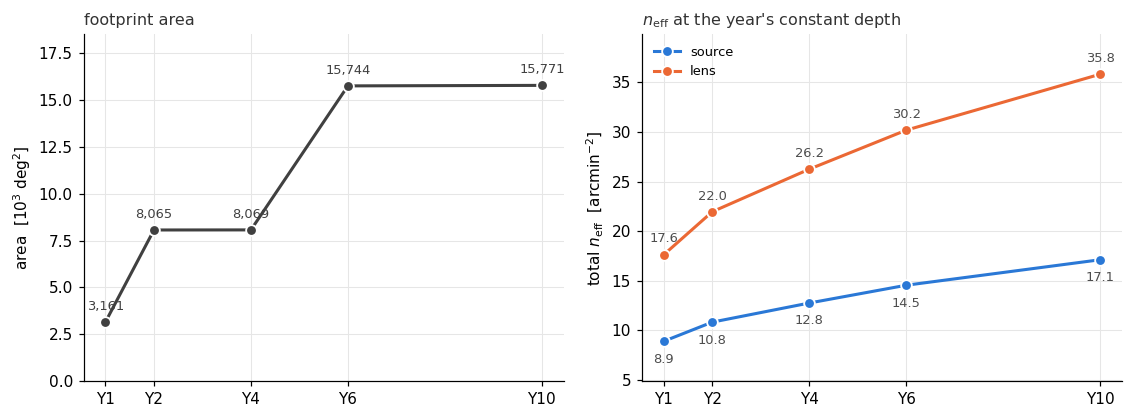

In [10]:
YEAR_X = np.array(YEARS)


def dress(ax):
    ax.grid(True, color="0.9", lw=0.7)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.set_xticks(YEAR_X)
    ax.set_xticklabels([f"Y{y}" for y in YEARS])


fig, (axA, axN) = plt.subplots(1, 2, figsize=(10.4, 3.9))
axA.plot(YEAR_X, survey["area"] / 1e3, "o-", color="0.25", lw=2, ms=7, mec="white", mew=1.2)
for y in YEARS:
    axA.annotate(f"{survey.loc[y, 'area']:,.0f}", (y, survey.loc[y, "area"] / 1e3), xytext=(0, 8),
                 textcoords="offset points", ha="center", fontsize=8.5, color="0.25")
axA.set_ylabel(r"area  [$10^3$ deg$^2$]")
axA.set_ylim(0, 18.5)
axA.set_title("footprint area", fontsize=10.5, loc="left", color="0.2")
dress(axA)

for col, key, lab, dy in ((SRC_C, "neff_src", "source", -14), (LENS_C, "neff_lens", "lens", 8)):
    axN.plot(YEAR_X, survey[key], "o-", color=col, lw=2, ms=7, mec="white", mew=1.2, label=lab)
    for y in YEARS:
        axN.annotate(f"{survey.loc[y, key]:.1f}", (y, survey.loc[y, key]), xytext=(0, dy),
                     textcoords="offset points", ha="center", fontsize=8.5, color="0.3")
axN.set_ylabel(r"total $n_{\rm eff}$  [arcmin$^{-2}$]")
axN.set_title(r"$n_{\rm eff}$ at the year's constant depth", fontsize=10.5, loc="left", color="0.2")
axN.legend(fontsize=8.5, frameon=False, loc="upper left")
axN.margins(y=0.15)
dress(axN)
fig.tight_layout()
fig.savefig("wfd_yearly_area_neff.png", dpi=130)
plt.show()


### The un-normalized $n(z)$

Each tomographic bin's shape $p_b(z)$ (unit area) times its $n_{\rm eff,b}$, so the curves are
in galaxies per arcmin$^2$ per unit redshift and their integral is that year's $n_{\rm eff}$.  Thin
lines are the individual bins, the thick line their sum.  Because the shapes are held fixed
(see caveats), the years differ only in the per-bin normalizations -- which still grow
faster for the high-redshift bins.

/tmp/ipykernel_30218/12534173.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8, frameon=False, loc="upper right")


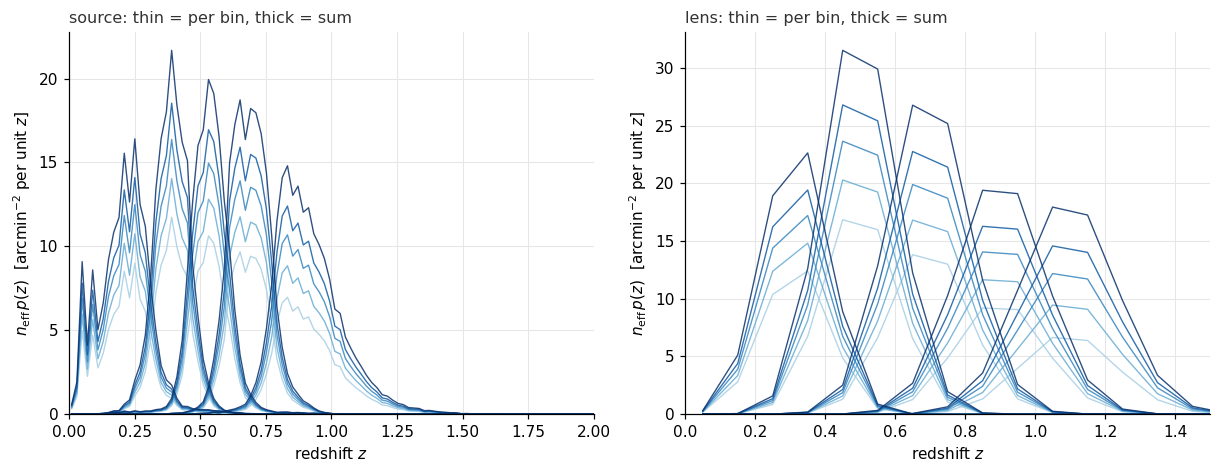

In [12]:
z_lens_grid = np.asarray(_lens_ref.z_lens)
nz_lens_shape = np.atleast_2d(np.asarray(_lens_ref.nz_lens, dtype=float))
nz_lens_shape = nz_lens_shape / np.trapezoid(nz_lens_shape, z_lens_grid, axis=1)[:, None]
nz_src_shape = nz_true / np.trapezoid(nz_true, z_grid, axis=1)[:, None]

YEAR_COLORS = dict(zip(YEARS, plt.cm.Blues(np.linspace(0.35, 1.0, len(YEARS)))))   # light -> dark = early -> late

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.4))
for ax, z, shape, neff, title, zmax in (
        (axes[0], z_grid, nz_src_shape, neff_src, "source", 2.0),
        (axes[1], z_lens_grid, nz_lens_shape, neff_lens, "lens", 1.5)):
    for y in YEARS:
        per_bin = neff[y][:, None] * shape
        for nb in per_bin:
            ax.plot(z, nb, color=YEAR_COLORS[y], lw=0.9, alpha=0.85)
        # ax.plot(z, per_bin.sum(axis=0), color=YEAR_COLORS[y], lw=2.2,
        #         label=f"Y{y}   $n_{{\\rm eff}}$ = {neff[y].sum():.1f} arcmin$^{{-2}}$")
    ax.set_xlim(0, zmax)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("redshift $z$")
    ax.set_ylabel(r"$n_{\rm eff}\,p(z)$  [arcmin$^{-2}$ per unit $z$]")
    ax.set_title(f"{title}: thin = per bin, thick = sum", fontsize=10.5, loc="left", color="0.2")
    ax.legend(fontsize=8, frameon=False, loc="upper right")
    ax.grid(True, color="0.9", lw=0.7)
    ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
fig.tight_layout()
fig.savefig("wfd_yearly_nz.png", dpi=130)
plt.show()


## 4. The forecast

One `FisherFlex` per (year, probe), with that year's per-bin $n_{\rm eff}$ (source and lens) and
$f_{\rm sky}=A/A_{\rm sky}$.  The reference row is the 17,500 deg$^2$, $i<24.1$ survey of the
two earlier notebooks, for orientation.

In [12]:
def build(mode, area, nsrc, nlens):
    return FisherFlex(
        nz_source=nz_true,
        photoz_prior_cov=PZ_PRIOR_COV,
        z_grid=z_grid,
        neff_source=nsrc,
        lens_neff=nlens,
        fsky=area / FULL_SKY_DEG2,
        sigma_e=SIGMA_E,
        mode=mode,
        nz_model="shift_stretch",
        y1=True,
        verbose=False,
    )


PROBES = ("cosmic_shear", "3x2pt")
CASES = [("ref 17.5k, i<24.1", AREA_REF, NEFF_SRC_FID, NEFF_LENS_FID)] + \
        [(f"Y{y}", survey.loc[y, "area"], neff_src[y], neff_lens[y]) for y in YEARS]

out = []
for label, area, nsrc, nlens in CASES:
    row = {"case": label, "area": area, "neff_src": nsrc.sum(), "neff_lens": nlens.sum()}
    for mode in PROBES:
        res = build(mode, area, nsrc, nlens).compute(parallel=True).forecast(**ELL_CUTS)
        tag = "CS" if mode == "cosmic_shear" else "3x2pt"
        row[f"{tag} sigma(S8)"] = res.s8()[1]
        row[f"{tag} FoM"] = res.fom("w_0", "w_a")
    out.append(row)
forecast = pd.DataFrame(out).set_index("case")
print(forecast.to_string(float_format=lambda v: f"{v:10.5g}"))


                        area   neff_src  neff_lens  CS sigma(S8)     CS FoM  3x2pt sigma(S8)  3x2pt FoM
case                                                                                                   
ref 17.5k, i<24.1      17500      9.065         18      0.014694     4.4772        0.0043451     26.781
Y1                    3160.8     8.8997     17.623      0.029837     1.9287        0.0098778      7.875
Y2                    8064.6     10.827     21.954      0.018133     3.4348        0.0058963     16.613
Y4                    8068.8     12.753     26.243      0.016239     3.9667        0.0055685     18.411
Y6                     15744     14.546     30.176      0.011064     6.8144        0.0038561     34.532
Y10                    15771     17.115     35.814     0.0099355     8.1118        0.0036526     38.647


In [13]:
summary = survey.copy()
summary.index = [f"Y{y}" for y in YEARS]
summary.index.name = "year"
for c in ("CS sigma(S8)", "CS FoM", "3x2pt sigma(S8)", "3x2pt FoM"):
    summary[c] = forecast.loc[summary.index, c].to_numpy()
summary = summary[["area", "fsky", "limited by", "m5", "i_lim", "delta_m", "neff_src", "neff_lens",
                   "CS sigma(S8)", "CS FoM", "3x2pt sigma(S8)", "3x2pt FoM"]]
summary.to_csv("wfd_yearly_forecast_summary.csv")
pd.concat({f"Y{y}": pd.DataFrame({"neff_src": neff_src[y], "neff_lens": neff_lens[y],
                                  "z_src": Z_SRC, "z_lens": Z_LENS},
                                 index=pd.Index(range(1, 6), name="bin")) for y in YEARS},
          names=["year"]).to_csv("wfd_yearly_neff_per_bin.csv")
print(summary.to_string(float_format=lambda v: f"{v:9.4g}"))


          area      fsky  limited by        m5     i_lim   delta_m  neff_src  neff_lens  CS sigma(S8)    CS FoM  3x2pt sigma(S8)  3x2pt FoM
year                                                                                                                                       
Y1        3161   0.07662  N far side     25.07     24.07  -0.03337       8.9      17.62       0.02984     1.929         0.009878      7.875
Y2        8065    0.1955    S centre     25.42     24.42    0.3228     10.83      21.95       0.01813     3.435         0.005896      16.61
Y4        8069    0.1956  S far side     25.73     24.73    0.6283     12.75      26.24       0.01624     3.967         0.005569      18.41
Y6   1.574e+04    0.3816         all     25.98     24.98    0.8752     14.55      30.18       0.01106     6.814         0.003856      34.53
Y10  1.577e+04    0.3823         all     26.29     25.29     1.189     17.12      35.81      0.009936     8.112         0.003653      38.65


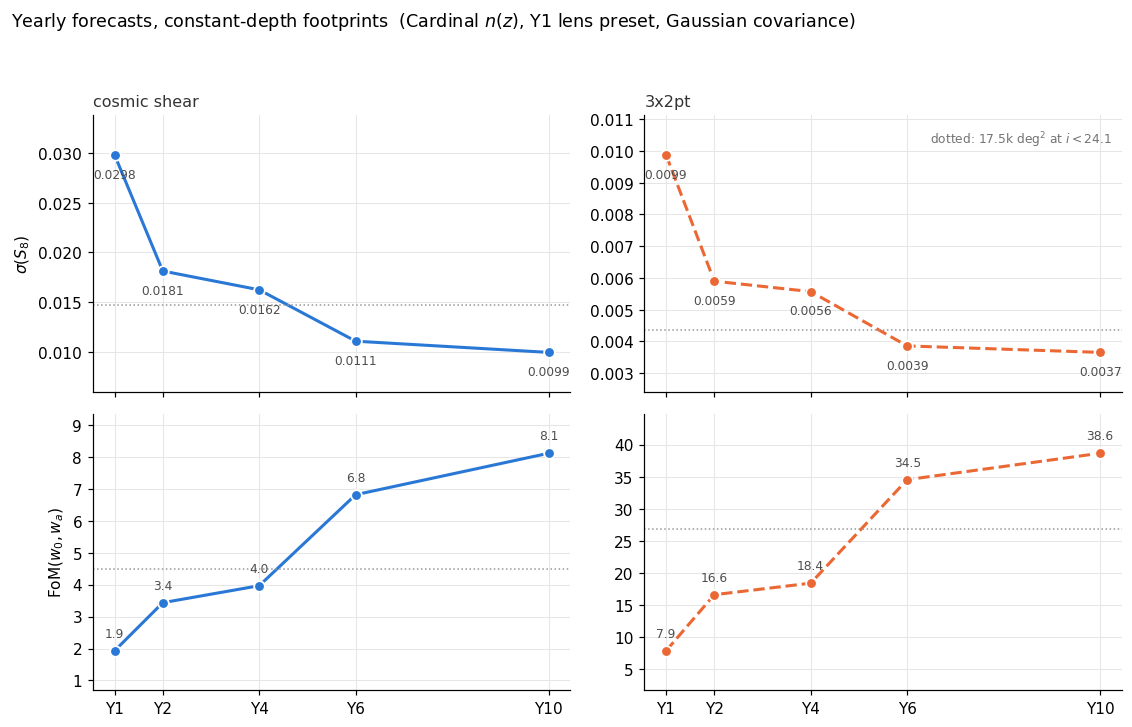

In [14]:
PROBE_STYLE = {"CS": dict(label="cosmic shear", color=SRC_C, ls="-"),
               "3x2pt": dict(label="3x2pt", color=LENS_C, ls="--")}

fig, axes = plt.subplots(2, 2, figsize=(10.4, 6.6), sharex=True)
for col, (tag, st) in enumerate(PROBE_STYLE.items()):
    for row_i, (key, ylab) in enumerate(((f"{tag} sigma(S8)", r"$\sigma(S_8)$"),
                                         (f"{tag} FoM", r"FoM$(w_0,w_a)$"))):
        ax = axes[row_i, col]
        yv = summary[key].to_numpy()
        ax.plot(YEAR_X, yv, color=st["color"], ls=st["ls"], lw=2, marker="o", ms=7,
                mec="white", mew=1.2)
        for x, v in zip(YEAR_X, yv):
            ax.annotate(f"{v:.4f}" if row_i == 0 else f"{v:.1f}", (x, v),
                        xytext=(0, 9 if row_i == 1 else -15), textcoords="offset points",
                        ha="center", fontsize=8, color="0.3")
        ax.axhline(forecast.loc["ref 17.5k, i<24.1", key], color="0.6", lw=1, ls=":")
        ax.margins(y=0.2)
        if row_i == 0:
            ax.set_title(st["label"], fontsize=10.5, loc="left", color="0.2")
        if col == 0:
            ax.set_ylabel(ylab)
        dress(ax)
axes[0, 1].annotate("dotted: 17.5k deg$^2$ at $i<24.1$", (0.98, 0.95), xycoords="axes fraction",
                    ha="right", va="top", fontsize=8, color="0.45")
fig.suptitle("Yearly forecasts, constant-depth footprints  (Cardinal $n(z)$, Y1 lens preset, Gaussian covariance)",
             fontsize=11.5, x=0.012, y=0.995, va="top", ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.955))
fig.savefig("wfd_yearly_forecast.png", dpi=130)
plt.show()


## Caveats

- **The $n(z)$ shape, the photo-z prior and the lens preset are the Y1 ones in every year.**
  Only the per-bin $n_{\rm eff}$ and $f_{\rm sky}$ move, as in the earlier notebooks.  That is a
  small extrapolation for Y2 ($\Delta m\approx+0.3$) but a large one for Y6/Y10 ($+0.9$ to
  $+1.2$ mag): a real Y10 sample has a deeper $n(z)$, more lensing efficiency per galaxy and
  higher lens bins, so the Y6/Y10 numbers here are **conservative** in the $n(z)$ sense.  For
  those years, swap in a Y10 $n(z)$ and the Y10 lens preset if one is available.
- **$\sigma_e$ is held at 0.26.**  Faint galaxies have noisier shapes, so the true $n_{\rm eff}$
  rises more slowly than raw counts -- this pushes the other way, most strongly at Y10.
- **$i_{\rm lim}=m_5-1$ is a convention.**  Shifting it by $\delta$ shifts every year's
  $i_{\rm lim}$ by $\delta$ together; the year-to-year *ordering* does not depend on it.
- **Box depth is the median, year depth is the shallowest box median.**  So roughly half the
  pixels of the limiting box sit *below* the adopted depth: the year's footprint is not
  strictly uniform at that depth.  A stricter rule (e.g. the 16th percentile, listed as `p16`
  in the box table) costs about 0.15-0.2 mag.
- **The southern far-side boxes are tiny after the $|b|$ cut** (37 deg$^2$), yet under the
  "shallowest box median" rule they can set the depth of a whole year: in Y4 this 37 deg$^2$
  box is the limiting one.  The $\delta<-75^\circ$ strip in Y6/Y10 (~440 deg$^2$) is excluded.
- **Gaussian covariance only** -- no non-Gaussian or super-sample term -- so absolute FoMs are
  optimistic, as noted in the earlier notebooks.
